In [1]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import os

In [2]:
def getData(observables, filename, treename):
    file = uproot.open(filename)
    if (len(file.keys())>0 and treename in file.keys()[0]):
        return (file[treename]).arrays(observables, library='pd')
    else:
        print(treename, "not found in", filename)
        return -1

In [3]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=True):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
plt.rcParams['font.size'] = 12

In [7]:
observables = ['runnumber','centrality','rho','jet_pt','jet_area','jet_neutral_fraction','jet_leading_track_charge',\
    'jet_subleading_track_pt','jet_subleading_track_charge']

In [8]:
df_array = []
filepath = '/vast/palmer/scratch/havener/ys668/useful/mb_day112_114/'
njet = 0
files = os.listdir(filepath)
for filename in files:
    print('reading in file', filename)
    df_temp = getData(observables, filepath+filename, "jet_tree")
    #print(type(df_temp))
    if (isinstance(df_temp, pd.core.frame.DataFrame) == False):
        continue
    df_array.append(df_temp)
    print('read in', df_temp.shape[0], 'jets')
    njet += df_temp.shape[0]
df = pd.concat([df for df in df_array])
print('total number of jets: ', df.shape[0])

reading in file mbjet.90873BA764EDD869B0E21039541007C2_0.root
read in 341910 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1.root
read in 274319 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_10.root
read in 339308 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_100.root
read in 334126 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1000.root
read in 334635 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1001.root
read in 190191 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1002.root
read in 44252 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1003.root
read in 37921 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1004.root
read in 27721 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1005.root
read in 96187 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1006.root
read in 305786 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1007.root
read in 15373

read in 324223 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1084.root
read in 288381 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1085.root
read in 257036 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1086.root
read in 313002 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1087.root
read in 339868 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1088.root
read in 324541 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1089.root
read in 319287 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_109.root
read in 337231 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1090.root
read in 219399 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1091.root
read in 94484 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1092.root
read in 37226 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1093.root
read in 53252 jets
reading in file mbjet.90873BA764EDD869B0E21039541

read in 345291 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1172.root
read in 339357 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1173.root
read in 339369 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1174.root
read in 305558 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1175.root
read in 341665 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1176.root
read in 320274 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1177.root
read in 299136 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1178.root
read in 145496 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1179.root
read in 306766 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_118.root
read in 276735 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1180.root
read in 343044 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1181.root
read in 327405 jets
reading in file mbjet.90873BA764EDD869B0E21039

read in 321758 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1260.root
read in 341923 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1261.root
read in 338171 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1262.root
read in 291045 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1263.root
read in 337980 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1264.root
read in 334710 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1265.root
read in 324710 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1266.root
read in 342912 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1267.root
read in 324093 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1268.root
read in 308295 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1269.root
read in 324920 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_127.root
read in 321684 jets
reading in file mbjet.90873BA764EDD869B0E21039

read in 341174 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1346.root
read in 336677 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1347.root
read in 274751 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1348.root
read in 333796 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1349.root
read in 257654 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_135.root
read in 287610 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1350.root
read in 339247 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1351.root
read in 324092 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1352.root
read in 338193 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1353.root
read in 296335 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1354.root
read in 333866 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1355.root
read in 289038 jets
reading in file mbjet.90873BA764EDD869B0E21039

read in 334424 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1432.root
read in 333025 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1433.root
read in 280424 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1434.root
read in 351770 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1435.root
read in 349710 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1436.root
read in 313778 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1437.root
read in 266734 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1438.root
read in 294210 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1439.root
read in 320518 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_144.root
read in 310833 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1440.root
read in 343545 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_1441.root
read in 339333 jets
reading in file mbjet.90873BA764EDD869B0E21039

... (9 outputs left out)

read in 338131 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_69.root
read in 342904 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_690.root
read in 336973 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_691.root
read in 336193 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_692.root
read in 338570 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_693.root
read in 253782 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_694.root
read in 303723 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_695.root
read in 337708 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_696.root
read in 322373 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_697.root
read in 239749 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_698.root
read in 340779 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_699.root
read in 308791 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_7.

read in 325366 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_778.root
read in 317454 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_779.root
read in 269552 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_78.root
read in 283642 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_780.root
read in 293026 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_781.root
read in 307610 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_782.root
read in 284724 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_783.root
read in 243138 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_784.root
read in 325547 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_785.root
read in 262066 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_786.root
read in 306819 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_787.root
read in 274856 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_78

read in 30917 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_866.root
read in 21742 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_867.root
read in 24484 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_868.root
read in 24957 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_869.root
read in 34116 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_87.root
read in 340024 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_870.root
read in 26642 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_871.root
read in 25479 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_872.root
read in 25472 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_873.root
read in 33251 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_874.root
read in 22643 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_875.root
read in 35328 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_876.root
read

read in 242117 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_955.root
read in 272543 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_956.root
read in 188266 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_957.root
read in 134745 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_958.root
read in 304344 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_959.root
read in 316908 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_96.root
read in 313169 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_960.root
read in 154769 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_961.root
read in 16839 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_962.root
read in 37479 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_963.root
read in 40737 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_964.root
read in 42189 jets
reading in file mbjet.90873BA764EDD869B0E21039541007C2_965.ro

In [9]:
df.eval('b_ch = jet_leading_track_charge*jet_subleading_track_charge', inplace=True)
df.eval('jet_pt_sub = jet_pt - rho*jet_area', inplace=True)

In [10]:
df_112_114 = applyCut(df, 'jet_subleading_track_pt > 0 and jet_neutral_fraction < 0.9')
df_112_114.shape[0]

498213400

In [11]:
df_array = []
filepath = '/gpfs/gibbs/project/havener/ys668/rc/isobar/mb_day115_117/'
njet = 0
files = os.listdir(filepath)
for filename in files:
    print('reading in file', filename)
    df_temp = getData(observables, filepath+filename, "jet_tree")
    #print(type(df_temp))
    if (isinstance(df_temp, pd.core.frame.DataFrame) == False):
        continue
    df_array.append(df_temp)
    print('read in', df_temp.shape[0], 'jets')
    njet += df_temp.shape[0]
df = pd.concat([df for df in df_array])
print('total number of jets: ', df.shape[0])

reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_280.root
read in 338754 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_222.root
read in 340861 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_362.root
read in 331756 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_115.root
read in 318263 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_748.root
read in 327227 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_540.root
read in 323898 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_576.root
read in 41469 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_229.root
read in 340541 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_345.root
read in 336175 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_662.root
read in 322470 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_560.root
read in 28716 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_343.root
read in 340144

read in 338108 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_349.root
read in 301172 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_534.root
read in 255690 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_47.root
read in 334777 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_494.root
read in 336566 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_363.root
read in 321494 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_398.root
read in 302642 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_822.root
read in 341069 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_385.root
read in 339820 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_74.root
read in 309016 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_722.root
read in 287299 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_82.root
read in 335310 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_440.

read in 268318 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_701.root
read in 118284 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_388.root
read in 317975 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_850.root
read in 323970 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_294.root
read in 286698 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_740.root
read in 339762 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_248.root
read in 340883 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_830.root
read in 342877 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_828.root
read in 303717 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_810.root
read in 338303 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_774.root
read in 327743 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_272.root
read in 317600 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_2

read in 324367 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_48.root
read in 338740 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_117.root
read in 338037 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_0.root
read in 336601 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_811.root
read in 303611 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_416.root
read in 342506 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_684.root
read in 23479 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_196.root
read in 323661 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_786.root
read in 334843 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_431.root
read in 283517 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_377.root
read in 290035 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_728.root
read in 293774 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_545.r

read in 333906 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_541.root
read in 337837 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_605.root
read in 113030 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_282.root
read in 331642 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_700.root
read in 3960 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_235.root
read in 321675 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_86.root
read in 318596 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_44.root
read in 318745 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_496.root
read in 319624 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_861.root
read in 320703 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_425.root
read in 302405 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_463.root
read in 285792 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_159.r

read in 304021 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_716.root
read in 335676 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_759.root
read in 237971 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_32.root
read in 269118 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_637.root
read in 287324 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_38.root
read in 314316 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_145.root
read in 326781 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_771.root
read in 336896 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_606.root
read in 150689 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_437.root
read in 317632 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_470.root
read in 289496 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_751.root
read in 282882 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_89.

read in 307577 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_33.root
read in 270253 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_656.root
read in 175300 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_694.root
read in 26040 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_374.root
read in 286060 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_358.root
read in 331065 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_156.root
read in 334005 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_383.root
read in 334426 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_149.root
read in 317549 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_331.root
read in 338367 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_300.root
read in 331464 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_481.root
read in 333982 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_359

read in 239922 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_617.root
read in 284181 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_31.root
read in 250681 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_625.root
read in 202723 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_594.root
read in 30940 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_472.root
read in 302595 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_665.root
read in 27199 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_712.root
read in 138066 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_607.root
read in 57727 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_223.root
read in 343045 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_812.root
read in 340962 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_832.root
read in 342491 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_767.r

read in 343379 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_551.root
read in 20855 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_3.root
read in 246493 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_522.root
read in 327592 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_103.root
read in 337577 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_527.root
read in 311443 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_296.root
read in 318953 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_723.root
read in 268357 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_782.root
read in 238938 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_307.root
read in 282821 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_599.root
read in 33009 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_451.root
read in 336459 jets
reading in file mbjet.6BA75F9149A4E34DF6AA608C33BAEF08_432.r

In [12]:
df.eval('b_ch = jet_leading_track_charge*jet_subleading_track_charge', inplace=True)
df.eval('jet_pt_sub = jet_pt - rho*jet_area', inplace=True)

In [13]:
df_115_117 = applyCut(df, 'jet_subleading_track_pt > 0 and jet_neutral_fraction < 0.9')
df_115_117.shape[0]

239241239

In [14]:
df_array = []
filepath = '/gpfs/gibbs/project/havener/ys668/rc/isobar/mb_day118/'
njet = 0
files = os.listdir(filepath)
for filename in files:
    print('reading in file', filename)
    df_temp = getData(observables, filepath+filename, "jet_tree")
    #print(type(df_temp))
    if (isinstance(df_temp, pd.core.frame.DataFrame) == False):
        continue
    df_array.append(df_temp)
    print('read in', df_temp.shape[0], 'jets')
    njet += df_temp.shape[0]
df = pd.concat([df for df in df_array])
print('total number of jets: ', df.shape[0])

reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_5.root
read in 308271 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_4.root
read in 291023 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_288.root
read in 319797 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_329.root
read in 37321 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_21.root
read in 338054 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_498.root
read in 221224 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_17.root
read in 304333 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_103.root
read in 333040 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_46.root
read in 250653 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_2.root
read in 333787 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_63.root
read in 336592 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_493.root
read in 329237 jets
rea

read in 126457 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_252.root
read in 340347 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_444.root
read in 337312 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_198.root
read in 252095 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_166.root
read in 335456 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_96.root
read in 116153 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_255.root
read in 343126 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_421.root
read in 296672 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_87.root
read in 337095 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_355.root
read in 255771 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_97.root
read in 337538 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_322.root
read in 25449 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_133.r

read in 320065 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_295.root
read in 26953 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_486.root
read in 305607 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_209.root
read in 201541 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_69.root
read in 330342 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_9.root
read in 328801 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_381.root
read in 284849 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_188.root
read in 337654 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_337.root
read in 24119 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_448.root
read in 320354 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_89.root
read in 37776 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_427.root
read in 336836 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_272.root

read in 337263 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_34.root
read in 303057 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_70.root
read in 341719 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_34.root
read in 325510 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_362.root
read in 325754 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_139.root
read in 335019 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_124.root
read in 221033 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_417.root
read in 244063 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_60.root
read in 312404 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_352.root
read in 316484 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_205.root
read in 320530 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_366.root
read in 286227 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_86.ro

read in 336541 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_99.root
read in 318221 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_433.root
read in 315322 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_207.root
read in 335376 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_141.root
read in 335201 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_78.root
read in 323013 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_479.root
read in 36577 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_83.root
read in 17451 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_185.root
read in 319311 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_287.root
read in 292183 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_82.root
read in 10933 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_342.root
read in 42583 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_116.root


read in 314563 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_416.root
read in 219084 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_97.root
read in 325170 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_111.root
read in 340131 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_363.root
read in 242837 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_484.root
read in 217677 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_23.root
read in 158913 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_80.root
read in 333984 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_268.root
read in 335933 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_8.root
read in 341191 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_85.root
read in 337614 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_164.root
read in 296370 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_149.roo

read in 337690 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_129.root
read in 312951 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_42.root
read in 217622 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_226.root
read in 336064 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_502.root
read in 288049 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_68.root
read in 299295 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_439.root
read in 264136 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_91.root
read in 327373 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_225.root
read in 337392 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_505.root
read in 287166 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_193.root
read in 337350 jets
reading in file mbjet.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_117.root
read in 335865 jets
reading in file mbjet.6F4C35CE2C9D667B8C100007E446D37C_36.r

In [15]:
df.eval('b_ch = jet_leading_track_charge*jet_subleading_track_charge', inplace=True)
df.eval('jet_pt_sub = jet_pt - rho*jet_area', inplace=True)

In [16]:
df_118 = applyCut(df, 'jet_subleading_track_pt > 0 and jet_neutral_fraction < 0.9')
df_118.shape[0]

175237136

In [17]:
df = pd.concat([df_112_114, df_115_117, df_118])

In [18]:
df['w'] = np.ones(df.shape[0])

In [19]:
df_central = applyCut(df, 'centrality >= 12 and b_ch!=0')
df_peripheral = applyCut(df, '0 <= centrality <= 5 and b_ch!=0')

Text(-10, 1e-08, 'Ru+Ru, Zr+Zr $\\sqrt{s_{\\mathrm{NN}}}=200$ GeV, 0-20%\nanti-$k_{\\mathrm{T}}$, $R=0.4$, $p_{\\mathrm{T}}>15$ GeV$/c$')

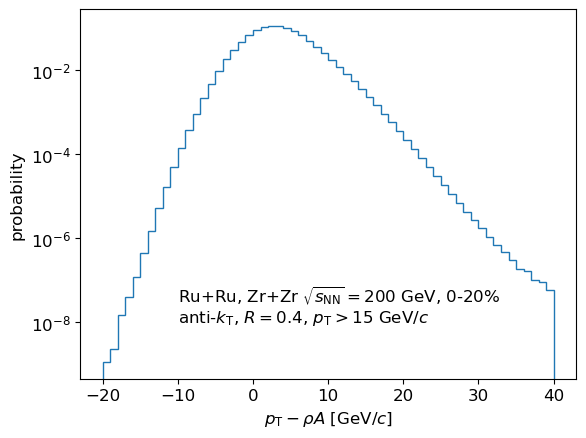

In [20]:
plt.hist(df_central['jet_pt_sub'], histtype='step', bins=np.arange(-20,41,1), density=True)
plt.yscale('log')
plt.ylabel('probability')
plt.xlabel(r'$p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.text(-10, 0.00000001, r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV, 0-20%'+'\nanti-$k_{\mathrm{T}}$, $R=0.4$, $p_{\mathrm{T}}>15$ GeV$/c$')

(array([1.0000000e+00, 2.0000000e+00, 1.3000000e+01, 3.5000000e+01,
       1.0500000e+02, 3.8300000e+02, 1.3020000e+03, 4.4940000e+03,
       1.3878000e+04, 4.1697000e+04, 1.1783300e+05, 3.1515800e+05,
       7.9120900e+05, 1.8589540e+06, 4.0562000e+06, 8.1980250e+06,
       1.5240063e+07, 2.5990047e+07, 4.0509162e+07, 5.7540244e+07,
       7.4484261e+07, 8.7974615e+07, 9.5233170e+07, 9.4754468e+07,
       8.6784570e+07, 7.3222674e+07, 5.7391974e+07, 4.2659161e+07,
       3.0726288e+07, 2.1688666e+07, 1.5040715e+07, 1.0281305e+07,
       6.9194860e+06, 4.5976920e+06, 3.0118150e+06, 1.9488540e+06,
       1.2500480e+06, 7.9027900e+05, 4.9651100e+05, 3.0849100e+05,
       1.9017800e+05, 1.1688500e+05, 7.1156000e+04, 4.3329000e+04,
       2.6481000e+04, 1.6151000e+04, 9.8400000e+03, 5.9710000e+03,
       3.6970000e+03, 2.3930000e+03, 1.4840000e+03, 9.3700000e+02,
       6.0300000e+02, 4.1300000e+02, 2.6000000e+02, 1.5900000e+02,
       1.4800000e+02, 8.6000000e+01, 7.9000000e+01, 5.2000000

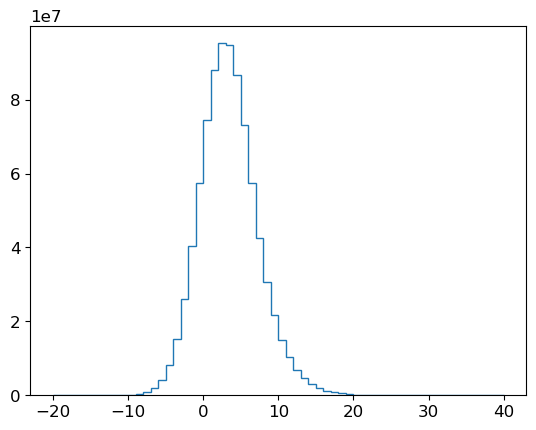

In [28]:
print(plt.hist(df_central['jet_pt_sub'], histtype='step', bins=np.arange(-20,41,1)))

In [33]:
df = applyCut(df, 'jet_pt_sub>20')

In [19]:
df_central = applyCut(df, 'centrality >= 12 and b_ch!=0')
df_peripheral = applyCut(df, '0 <= centrality <= 5 and b_ch!=0')

In [22]:
df_central_array = [   df_central[(df_central.jet_pt_sub>20) & (df_central.jet_pt_sub<25)],\
                       df_central[(df_central.jet_pt_sub>25) & (df_central.jet_pt_sub<30)],\
                       df_central[(df_central.jet_pt_sub>30) & (df_central.jet_pt_sub<40)] ]

In [23]:
df_peripheral_array = [ df_peripheral[(df_peripheral.jet_pt_sub>20) & (df_peripheral.jet_pt_sub<25)],\
                       df_peripheral[(df_peripheral.jet_pt_sub>25) & (df_peripheral.jet_pt_sub<30)],\
                       df_peripheral[(df_peripheral.jet_pt_sub>30) & (df_peripheral.jet_pt_sub<40)] ]

In [24]:
rc_central_array = []
rc_err_central_array = []
for i in range(0, len(df_central_array)):
    rc_central_array.append(getRcAndErr(df_central_array[i], 'b_ch')[0])
    rc_err_central_array.append(getRcAndErr(df_central_array[i], 'b_ch')[1])

In [25]:
rc_peripheral_array = []
rc_err_peripheral_array = []
for i in range(0, len(df_peripheral_array)):
    rc_peripheral_array.append(getRcAndErr(df_peripheral_array[i], 'b_ch')[0])
    rc_err_peripheral_array.append(getRcAndErr(df_peripheral_array[i], 'b_ch')[1])

In [26]:
print(rc_central_array)
print(rc_err_central_array)
print(rc_peripheral_array)
print(rc_err_peripheral_array)

[-0.03312508788493602, -0.06764427625354778, -0.13290689410092396]
[0.0014931675281151713, 0.005114643460969961, 0.015255354367798186]
[-0.31700680272108844, -0.2966360856269113, -0.38461538461538464]
[0.024736800741077605, 0.052811100465981226, 0.09051513929454648]


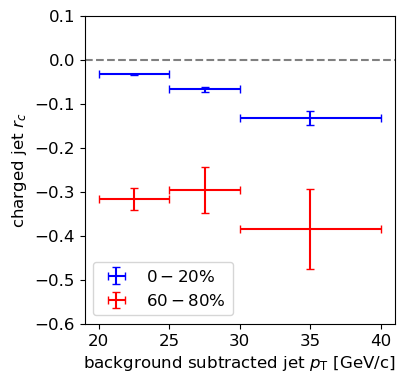

In [27]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_central_array, xerr=[2.5, 2.5, 5], yerr=rc_err_central_array, capsize=3, color='b', ls='none', label='$0-20\%$')
plt.errorbar([22.5, 27.5, 35], rc_peripheral_array, xerr=[2.5, 2.5, 5], yerr=rc_err_peripheral_array, capsize=3, color='r', ls='none', label='$60-80\%$')
plt.xlabel('background subtracted jet $p_{\mathrm{T}}$ [GeV/c]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='lower left')